# GLESKit manuscript figures and tables

This notebook contains the analysis code and saved outputs for main Figures 3–6, Extended Data Figures 2–5, and Extended Data Tables 1–3. The embedded previews come from the compiled manuscript figures and are visible without executing the notebook.

Execution requires the original evaluation run summaries, task registry and session exports under `var/` in a GLESKit checkout. The [Zenodo supplement](https://doi.org/10.5281/zenodo.23592806) provides numerical source data and reviewed evaluation records for inspecting the reported results.

Read the [GLESKit preprint](https://www.biorxiv.org/content/10.64898/2026.10.25.761689v1) for the figure captions and evaluation methods.


In [1]:
from __future__ import annotations

from collections import Counter
import json
from pathlib import Path
import re
import sys
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats


def locate_root() -> Path:
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'src').is_dir():
            return candidate
    raise RuntimeError('Could not locate the GLESKit repository root.')


ROOT = locate_root()
SOURCE_ROOT = str(ROOT / 'src')
if SOURCE_ROOT not in sys.path:
    sys.path.insert(0, SOURCE_ROOT)

from gleskit_mcp.eval import EvaluationResults

REGISTRY_PATH = ROOT / 'var' / 'repobench' / 'hf_repo' / 'RepoBench.jsonl'
if not REGISTRY_PATH.is_file():
    raise FileNotFoundError(
        'Running this notebook requires the original task registry and evaluation runs. '
        'The saved figures and tables are available in the notebook without running it.'
    )

OUTPUT_DIR = ROOT / 'notebooks' / 'eval' / 'paper_outputs'
FIGURE_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

MM_TO_INCH = 1 / 25.4
SINGLE_COLUMN_WIDTH = 89 * MM_TO_INCH
DOUBLE_COLUMN_WIDTH = 183 * MM_TO_INCH
MAX_FIGURE_HEIGHT = 170 * MM_TO_INCH
PAGE_WIDTH = DOUBLE_COLUMN_WIDTH
SCORE_DECIMALS = 3
SCORE_FORMAT = f'{{:.{SCORE_DECIMALS}f}}'

PALETTE = {
    'indigo': '#47469D',
    'periwinkle': '#817DD8',
    'powder_blue': '#A4B2E2',
    'magenta': '#B62E7F',
    'coral': '#D86345',
    'sand': '#E1B79A',
    'lavender_grey': '#B8B6C1',
    'jade': '#4F927F',
    'ink': '#29283A',
    'mid_grey': '#747380',
    'light_grey': '#D8D7DE',
    'pale_grey': '#F1F0F4',
}
CATEGORY_ORDER = ['unsupported', 'weak', 'partial', 'mostly_supported', 'accept']
CATEGORY_LABELS = {
    'unsupported': 'Unsupported',
    'weak': 'Weak',
    'partial': 'Partial',
    'mostly_supported': 'Mostly supported',
    'accept': 'Accept',
}
CATEGORY_COLORS = {
    'unsupported': PALETTE['coral'],
    'weak': PALETTE['lavender_grey'],
    'partial': PALETTE['sand'],
    'mostly_supported': PALETTE['periwinkle'],
    'accept': PALETTE['indigo'],
}
OUTCOME_ORDER = ['positive_score', 'substantive_zero', 'interrupted_zero', 'no_answer', 'judge_failure']
OUTCOME_LABELS = {
    'positive_score': 'Positive score',
    'substantive_zero': 'Substantive zero',
    'interrupted_zero': 'Interrupted zero',
    'no_answer': 'No answer',
    'judge_failure': 'Judge failure',
}
OUTCOME_COLORS = {
    'positive_score': PALETTE['indigo'],
    'substantive_zero': PALETTE['coral'],
    'interrupted_zero': PALETTE['sand'],
    'no_answer': PALETTE['lavender_grey'],
    'judge_failure': PALETTE['magenta'],
}
FAMILY_ORDER = ['biomarker', 'disease_context', 'mechanism']
FAMILY_LABELS = {'biomarker': 'Biomarker', 'disease_context': 'Disease context', 'mechanism': 'Mechanism'}
FAMILY_COLORS = {'biomarker': PALETTE['sand'], 'disease_context': PALETTE['indigo'], 'mechanism': PALETTE['jade']}
MODEL_COLORS = {'Terra': PALETTE['indigo'], 'DeepSeek': PALETTE['coral']}
SPECIES_COLORS = {
    'Homo sapiens': PALETTE['indigo'],
    'Mus musculus': PALETTE['jade'],
    'Pseudomonas aeruginosa': PALETTE['sand'],
}

SCORE_CMAP = LinearSegmentedColormap.from_list('gleskit_score', ['#FAFAFC', PALETTE['powder_blue'], PALETTE['indigo']])
POSITIVE_CMAP = LinearSegmentedColormap.from_list('gleskit_positive', ['#FAFAFC', '#BFD8CF', PALETTE['jade']])
FIGURE_AUDIT = []

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica'],
    'font.size': 6.2,
    'axes.titlesize': 7.0,
    'axes.labelsize': 6.5,
    'xtick.labelsize': 5.8,
    'ytick.labelsize': 5.8,
    'legend.fontsize': 5.7,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': PALETTE['ink'],
    'axes.linewidth': 0.65,
    'axes.grid': False,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 2.6,
    'ytick.major.size': 2.6,
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'xtick.color': PALETTE['ink'],
    'ytick.color': PALETTE['ink'],
    'text.color': PALETTE['ink'],
    'axes.labelcolor': PALETTE['ink'],
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'legend.frameon': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})


def mm(value: float) -> float:
    return value * MM_TO_INCH


def set_panel_title(axis: plt.Axes, letter: str, title: str) -> None:
    axis.set_title(f'{letter}  {title}', loc='left', fontweight='bold', fontsize=7.0, pad=5)


def short_bix_label(value: object) -> str:
    return str(value).removeprefix('bix-')


def draw_dumbbell(
    axis: plt.Axes,
    y: np.ndarray,
    first: np.ndarray,
    second: np.ndarray,
    *,
    first_label: str,
    second_label: str,
    first_color: str,
    second_color: str,
    size: float = 22,
) -> None:
    axis.hlines(y, np.minimum(first, second), np.maximum(first, second), color=PALETTE['light_grey'], linewidth=0.8, zorder=1)
    axis.scatter(first, y, marker='o', s=size, color=first_color, edgecolor='white', linewidth=0.45, label=first_label, zorder=3)
    axis.scatter(second, y, marker='o', s=size, color=second_color, edgecolor='white', linewidth=0.45, label=second_label, zorder=4)



def save_figure(fig: plt.Figure, stem: str) -> tuple[Path, Path]:
    width, height = fig.get_size_inches()
    if not np.isclose(width, DOUBLE_COLUMN_WIDTH, atol=1e-6):
        raise ValueError(f'{stem} width is {width:.6f} in, expected {DOUBLE_COLUMN_WIDTH:.6f} in.')
    if height > MAX_FIGURE_HEIGHT + 1e-6:
        raise ValueError(f'{stem} height exceeds 170 mm.')
    visible_gridlines = sum(
        line.get_visible()
        for axis in fig.axes
        for line in (*axis.get_xgridlines(), *axis.get_ygridlines())
    )
    if visible_gridlines:
        raise ValueError(f'{stem} contains {visible_gridlines} visible background gridlines.')
    png = FIGURE_DIR / f'{stem}.png'
    pdf = FIGURE_DIR / f'{stem}.pdf'
    fig.savefig(png, dpi=600, facecolor='white')
    fig.savefig(pdf, facecolor='white')
    FIGURE_AUDIT.append({'stem': stem, 'width_mm': width / MM_TO_INCH, 'height_mm': height / MM_TO_INCH, 'gridlines': visible_gridlines})
    return png, pdf



def score_interval(values: pd.Series) -> dict[str, float]:
    scores = pd.to_numeric(values, errors='coerce').dropna()
    n = len(scores)
    mean = scores.mean() if n else np.nan
    se = scores.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    half_width = stats.t.ppf(0.975, n - 1) * se if n > 1 else np.nan
    return {'n': n, 'mean': mean, 'se': se, 'ci_lower': mean - half_width, 'ci_upper': mean + half_width}


def apply_bixbench_committee_scores(data: pd.DataFrame) -> pd.DataFrame:
    """Return uncapped weighted scores from the three saved specialist verdicts."""
    result = data.copy()
    valid_verdict = result['normalized_score'].notna()
    levels = {category: level for level, category in enumerate(CATEGORY_ORDER)}
    statistics = result['judge_stats_category'].map(levels)
    biology = result['judge_biology_category'].map(levels)
    evidence = result['judge_evidence_category'].map(levels)
    numeric = result['numeric'].eq(1)
    weighted_level = (
        statistics * np.where(numeric, 0.55, 0.25)
        + biology * np.where(numeric, 0.20, 0.40)
        + evidence * np.where(numeric, 0.25, 0.35)
    )
    result['stored_final_score'] = result['normalized_score']
    result['normalized_score'] = weighted_level.div(4).where(valid_verdict)
    category_index = np.floor(weighted_level + 0.5).clip(0, 4)
    result['committee_category'] = pd.Series(
        np.where(valid_verdict, category_index.map(dict(enumerate(CATEGORY_ORDER))), pd.NA),
        index=result.index,
        dtype='string',
    )
    return result


def split_values(value: object) -> list[str]:
    if not isinstance(value, str) or not value.strip():
        return []
    return [part.strip() for part in value.split(';') if part.strip()]


def save_table(frame: pd.DataFrame, stem: str, *, column_format: str, formatters: dict | None = None) -> None:
    frame.to_csv(TABLE_DIR / f'{stem}.csv', index=False)
    latex = frame.to_latex(
        index=False,
        escape=False,
        column_format=column_format,
        formatters=formatters,
    )
    (TABLE_DIR / f'{stem}.tex').write_text(latex, encoding='utf-8')


def extract_repobench_usage(run_root: Path) -> pd.DataFrame:
    rows = []
    for episode_path in sorted((run_root / 'episodes').glob('*/episode.json')):
        episode = json.loads(episode_path.read_text(encoding='utf-8'))
        attempts = [attempt for attempt in episode.get('attempts', []) if attempt.get('report_saved')]
        if not attempts:
            raise ValueError(f'No report-saving attempt in {episode_path}.')
        raw_path = Path(attempts[-1]['session_export_path'])
        candidates = [raw_path, run_root / raw_path, episode_path.parent / raw_path]
        session_path = next((path for path in candidates if path.is_file()), None)
        if session_path is None:
            raise FileNotFoundError(f'Missing session export for {episode["task_id"]}.')
        payload = json.loads(session_path.read_text(encoding='utf-8'))
        session = payload.get('session', {})
        keys = ('tokens_input', 'tokens_output', 'tokens_reasoning', 'tokens_cache_read')
        if any(key in session for key in keys):
            usage = {key: int(session.get(key, 0) or 0) for key in keys}
        else:
            usage = {key: 0 for key in keys}
            for message in payload.get('messages', []):
                tokens = (message.get('data', {}) or {}).get('tokens') or {}
                cache = tokens.get('cache') or {}
                usage['tokens_input'] += int(tokens.get('input', 0) or 0)
                usage['tokens_output'] += int(tokens.get('output', 0) or 0)
                usage['tokens_reasoning'] += int(tokens.get('reasoning', 0) or 0)
                usage['tokens_cache_read'] += int(cache.get('read', 0) or 0)
        if not sum(usage.values()):
            raise ValueError(f'No token usage captured for {episode["task_id"]}.')
        rows.append({'item_id': str(episode['task_id']), **usage})
    return pd.DataFrame(rows)


def add_costs(data: pd.DataFrame, pricing: dict[str, float]) -> pd.DataFrame:
    result = EvaluationResults.add_token_costs(data, pricing, output_column='estimated_cost_usd')
    result['total_tokens'] = result[['tokens_input', 'tokens_output', 'tokens_reasoning', 'tokens_cache_read']].sum(axis=1)
    return result


results = EvaluationResults(ROOT)


## Persisted cohorts and validation

The assertions verify that the saved evaluation runs match the cohorts and scores used for the manuscript analysis.


In [2]:
GRB_RUNS = [
    'repobench_deepseek_skilled_subset5_repoids_20260727',
    'repobench_deepseek_skilled_remaining10_20260729',
]
BIX_RUNS = [
    'deepseek_cli_clean_20260711',
    'deepseek_cli_clean_20260713_remaining47',
]
SEGMENT_LABELS = {
    'bixbench:deepseek_cli_clean_20260711': 'First 20 questions',
    'bixbench:deepseek_cli_clean_20260713_remaining47': 'Remaining 47 questions',
}

registry_records = [json.loads(line) for line in REGISTRY_PATH.read_text(encoding='utf-8').splitlines() if line.strip()]
registry = pd.DataFrame(registry_records)

grb = results.merge_runs(
    GRB_RUNS,
    benchmark='repobench',
    include_usage=False,
    include_judge_details=True,
)
grb = grb.merge(
    registry[['task_id', 'question_id', 'title', 'report_type', 'domain']],
    left_on='item_id', right_on='task_id', how='left', validate='one_to_one', suffixes=('', '_registry'),
)
for column in ('report_type',):
    registry_column = f'{column}_registry'
    if registry_column in grb:
        grb[column] = grb[column].fillna(grb[registry_column])
grb['family_order'] = grb['report_type'].map({name: index for index, name in enumerate(FAMILY_ORDER)})
grb['question_number'] = grb['question_id'].str.extract(r'(\d+)').astype(int)
grb = grb.sort_values(['family_order', 'question_number']).reset_index(drop=True)

specialist_columns = {
    'Biomedical content': 'biomedical_content_category',
    'Evidence support': 'evidence_support_category',
    'Provenance quality': 'provenance_quality_category',
    'Template compliance': 'template_compliance_category',
}
level_map = {category: level for level, category in enumerate(CATEGORY_ORDER)}
for label, column in specialist_columns.items():
    grb[label] = grb[column].map(level_map)

assert len(grb) == 15 and grb['item_id'].is_unique
assert np.isclose(grb['normalized_score'].mean(), 0.9041666666666667)
assert int(grb['review_required'].sum()) == 10
assert grb['Template compliance'].eq(4).all()

study = results.merge_runs(
    BIX_RUNS,
    benchmark='bixbench',
    include_usage=False,
    include_bixbench_metadata=True,
    include_judge_details=True,
)
study = apply_bixbench_committee_scores(study)
study['run_segment'] = study['source_run'].map(SEGMENT_LABELS)
study['run_segment'] = pd.Categorical(study['run_segment'], list(SEGMENT_LABELS.values()), ordered=True)
assert len(study) == 67 and study['item_id'].is_unique
assert study['species'].value_counts().to_dict() == {
    'Homo sapiens': 41,
    'Mus musculus': 13,
    'Pseudomonas aeruginosa': 13,
}

committee_scores = pd.to_numeric(study['normalized_score'], errors='coerce')
answered = study['answer_present'].eq(True).fillna(False)
formal_completed_answer = (
    answered
    & study['answer_source'].astype('string').eq('agent').fillna(False)
    & study['status'].astype('string').eq('completed').fillna(False)
)
outcomes = pd.Series(pd.NA, index=study.index, dtype='string')
outcomes.loc[committee_scores.gt(0)] = 'positive_score'
outcomes.loc[committee_scores.eq(0) & formal_completed_answer] = 'substantive_zero'
outcomes.loc[committee_scores.eq(0) & ~formal_completed_answer] = 'interrupted_zero'
outcomes.loc[~answered] = 'no_answer'
outcomes.loc[answered & committee_scores.isna()] = 'judge_failure'
assert outcomes.notna().all()
study['outcome_class'] = pd.Categorical(outcomes, OUTCOME_ORDER, ordered=True)
outcome_counts = study['outcome_class'].value_counts().reindex(OUTCOME_ORDER, fill_value=0)
assert outcome_counts.to_dict() == {
    'positive_score': 47,
    'substantive_zero': 2,
    'interrupted_zero': 7,
    'no_answer': 9,
    'judge_failure': 2,
}
assert int(study['answer_present'].eq(True).sum()) == 58
assert int(study['normalized_score'].notna().sum()) == 56

display(pd.DataFrame({
    'cohort': ['GeneReportBench', 'BixBench'],
    'items': [len(grb), len(study)],
    'valid committee scores': [grb['normalized_score'].notna().sum(), study['normalized_score'].notna().sum()],
}))

,cohort,items,valid committee scores
0,GeneReportBench,15,15
1,BixBench,67,56


## Main figures

### Figure 3. GeneReportBench report scores and specialist verdicts

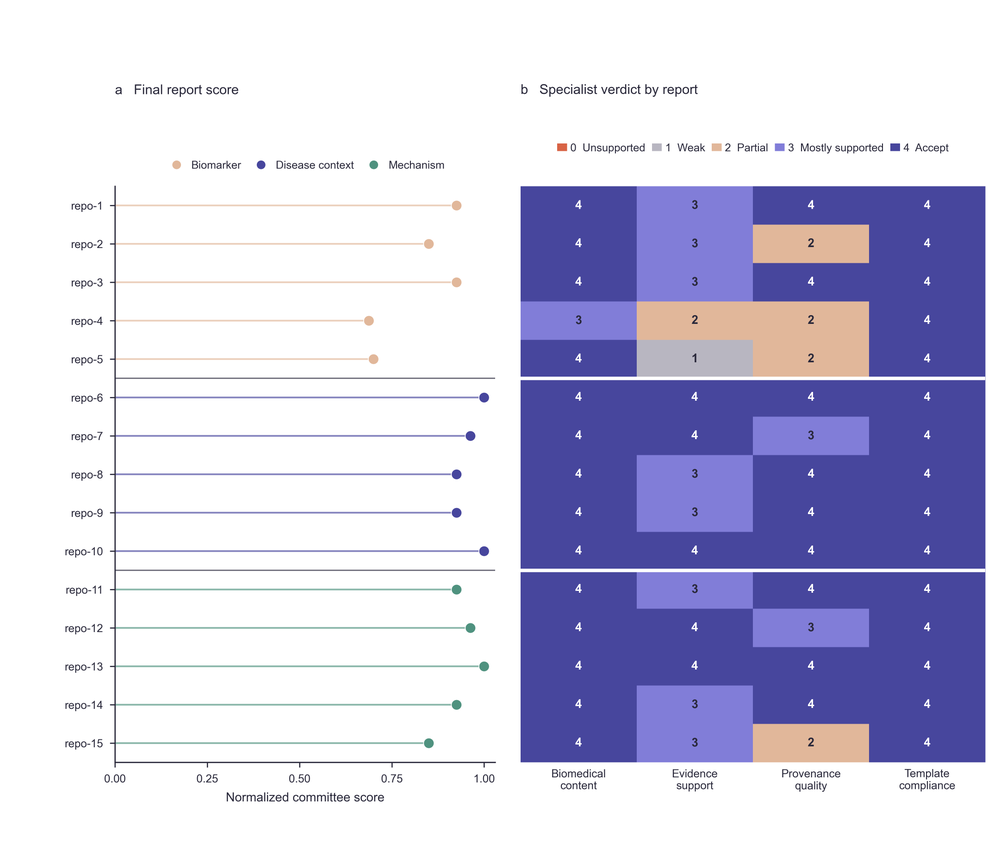

In [3]:
fig = plt.figure(figsize=(PAGE_WIDTH, mm(155)))
grid = fig.add_gridspec(1, 2, width_ratios=[1.08, 1.32], wspace=0.06)
ax_score = fig.add_subplot(grid[0, 0])
ax_heat = fig.add_subplot(grid[0, 1], sharey=ax_score)

y = np.arange(len(grb))

for index, row in grb.iterrows():
    family = row['report_type']
    color = FAMILY_COLORS[family]
    ax_score.hlines(index, 0, row['normalized_score'], color=color, linewidth=0.9, alpha=0.65, zorder=1)
    ax_score.scatter(row['normalized_score'], index, s=30, marker='o', color=color, edgecolor='white', linewidth=0.4, zorder=3)

ax_score.set_xlim(0, 1.03)
ax_score.set_xticks([0, 0.25, 0.50, 0.75, 1.00])
ax_score.set_xlabel('Normalized committee score')
ax_score.set_yticks(y, grb['question_id'].str.replace('-q1', '', regex=False))
ax_score.set_ylim(len(grb) - 0.5, -0.5)
ax_score.set_title('a   Final report score', loc='left', y=1.14)

heat_columns = list(specialist_columns)
heat = grb[heat_columns].to_numpy(dtype=int)
cmap = ListedColormap([CATEGORY_COLORS[name] for name in CATEGORY_ORDER])
norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), cmap.N)

ax_heat.imshow(heat, cmap=cmap, norm=norm, aspect='auto', origin='upper')

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat[i, j]
        color = 'white' if value in {0, 4} else PALETTE['ink']
        ax_heat.text(j, i, str(value), ha='center', va='center', color=color, fontsize=6.2, fontweight='bold')

ax_heat.set_xticks(range(len(heat_columns)), ['Biomedical\ncontent', 'Evidence\nsupport', 'Provenance\nquality', 'Template\ncompliance'])
ax_heat.tick_params(axis='y', left=False, labelleft=False)
ax_heat.tick_params(axis='x', length=0)
ax_heat.set_title('b   Specialist verdict by report', loc='left', y=1.14)

for spine in ax_heat.spines.values():
    spine.set_visible(False)

for boundary in [4.5, 9.5]:
    ax_score.axhline(boundary, color=PALETTE['mid_grey'], linewidth=0.7)
    ax_heat.axhline(boundary, color='white', linewidth=1.8)

family_handles = [
    Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=FAMILY_COLORS[name],
           markeredgecolor='white', markersize=5.5, label=FAMILY_LABELS[name])
    for name in FAMILY_ORDER
]

ax_score.legend(handles=family_handles, loc='lower center', bbox_to_anchor=(0.5, 1.01),
                ncol=3, frameon=False, columnspacing=0.8, handletextpad=0.35)

category_handles = [
    Patch(facecolor=CATEGORY_COLORS[name], edgecolor='none',
          label=f'{level}  {CATEGORY_LABELS[name]}')
    for level, name in enumerate(CATEGORY_ORDER)
]

ax_heat.legend(handles=category_handles, loc='lower center', bbox_to_anchor=(0.5, 1.04),
               ncol=5, frameon=False, columnspacing=0.6, handlelength=0.9, handletextpad=0.3)

fig.subplots_adjust(left=0.115, right=0.985, top=0.78, bottom=0.10)
save_figure(fig, 'fig3_genereportbench_results')
plt.show()

### Figure 4. BixBench outcome accounting and scope-aware performance

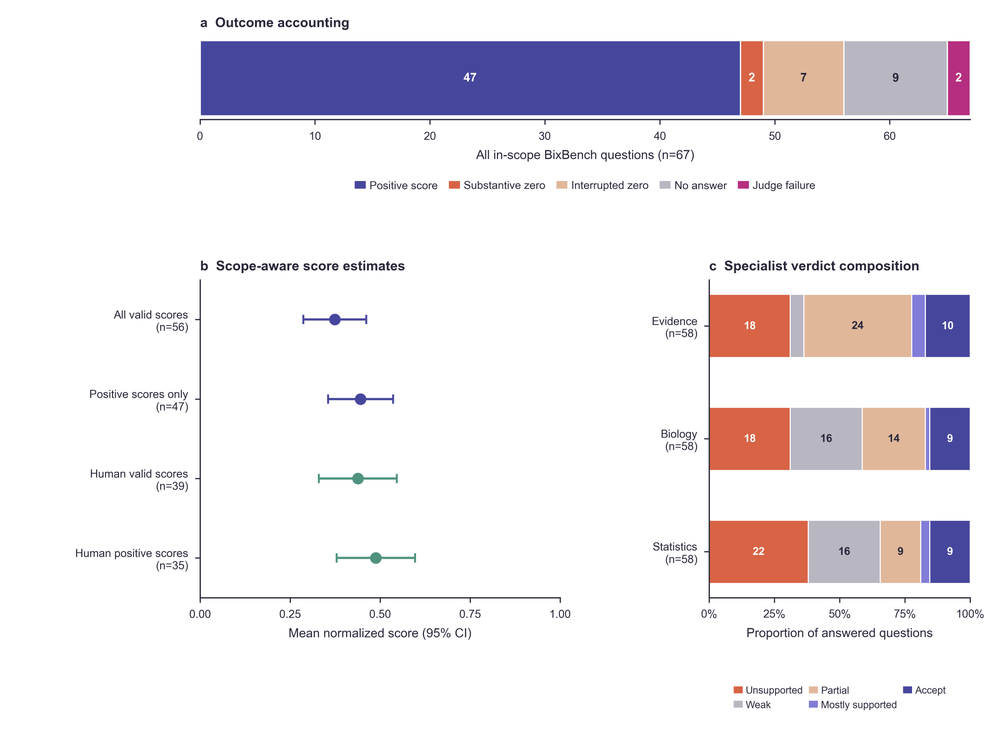

In [4]:
summary_outcomes = pd.DataFrame({
    'category': [OUTCOME_LABELS[name] for name in OUTCOME_ORDER],
    'n': [int(outcome_counts[name]) for name in OUTCOME_ORDER],
})
estimate_groups = [
    ('All valid scores', study['normalized_score']),
    ('Positive scores only', study.loc[study['normalized_score'].gt(0), 'normalized_score']),
    ('Human valid scores', study.loc[study['species'].eq('Homo sapiens'), 'normalized_score']),
    ('Human positive scores', study.loc[study['species'].eq('Homo sapiens') & study['normalized_score'].gt(0), 'normalized_score']),
]
summary_estimates = pd.DataFrame([
    {'group': group, **score_interval(values)} for group, values in estimate_groups
])
assert summary_outcomes.set_index('category')['n'].astype(int).to_dict() == {
    'Positive score': 47, 'Substantive zero': 2, 'Interrupted zero': 7, 'No answer': 9, 'Judge failure': 2,
}
assert summary_estimates.set_index('group')['n'].astype(int).to_dict() == {
    'All valid scores': 56, 'Positive scores only': 47, 'Human valid scores': 39, 'Human positive scores': 35,
}
assert np.isclose(summary_estimates.set_index('group').loc['All valid scores', 'mean'], 0.3741071428571429)
assert np.isclose(summary_estimates.set_index('group').loc['Human valid scores', 'mean'], 0.4381410256410257)

role_columns = {'Statistics': 'judge_stats_category', 'Biology': 'judge_biology_category', 'Evidence': 'judge_evidence_category'}
answered_study = study.loc[study['answer_present'].eq(True)].copy()
specialist_counts = {
    role: answered_study[column].astype('string').value_counts().reindex(CATEGORY_ORDER, fill_value=0).astype(int)
    for role, column in role_columns.items()
}
assert all(int(counts.sum()) == 58 for counts in specialist_counts.values())

fig = plt.figure(figsize=(PAGE_WIDTH, mm(135)))
grid = fig.add_gridspec(2, 2, height_ratios=[0.62, 2.38], width_ratios=[1.38, 1.0], hspace=0.80, wspace=0.48)
ax_outcome = fig.add_subplot(grid[0, :])
ax_estimate = fig.add_subplot(grid[1, 0])
ax_specialist = fig.add_subplot(grid[1, 1])

left = 0
for row in summary_outcomes.itertuples():
    key = next(name for name, label in OUTCOME_LABELS.items() if label == row.category)
    count = int(row.n)
    ax_outcome.barh([0], [count], left=left, height=0.52, color=OUTCOME_COLORS[key], edgecolor='white', linewidth=0.65)
    text_color = 'white' if key in {'positive_score', 'substantive_zero', 'judge_failure'} else PALETTE['ink']
    ax_outcome.text(left + count / 2, 0, str(count), ha='center', va='center', color=text_color, fontsize=6.2, fontweight='bold')
    left += count
ax_outcome.set_xlim(0, 67)
ax_outcome.set_yticks([])
ax_outcome.set_xlabel('All in-scope BixBench questions (n=67)')
set_panel_title(ax_outcome, 'a', 'Outcome accounting')
ax_outcome.spines['left'].set_visible(False)
ax_outcome.legend(
    handles=[Patch(facecolor=OUTCOME_COLORS[name], edgecolor='none', label=OUTCOME_LABELS[name]) for name in OUTCOME_ORDER],
    loc='upper center', bbox_to_anchor=(0.5, -0.62), ncol=5, columnspacing=1.0, handlelength=1.0, handletextpad=0.35,
)

for index, row in summary_estimates.reset_index(drop=True).iterrows():
    human = row['group'].startswith('Human')
    color = PALETTE['jade'] if human else PALETTE['indigo']
    ax_estimate.errorbar(
        row['mean'], index,
        xerr=np.array([[row['mean'] - row['ci_lower']], [row['ci_upper'] - row['mean']]]),
        fmt='o', color=color, markerfacecolor=color, markeredgecolor=color, markersize=5.0, capsize=2.4, linewidth=1.15,
    )
ax_estimate.set_xlim(0, 1)
ax_estimate.set_xticks([0, 0.25, 0.50, 0.75, 1.00])
ax_estimate.set_yticks(range(len(summary_estimates)), [f'{row.group}\n(n={int(row.n)})' for row in summary_estimates.itertuples()])
ax_estimate.set_ylim(len(summary_estimates) - 0.5, -0.5)
ax_estimate.set_xlabel('Mean normalized score (95% CI)')
set_panel_title(ax_estimate, 'b', 'Scope-aware score estimates')

role_order = ['Statistics', 'Biology', 'Evidence']
matrix = pd.DataFrame(specialist_counts).T.reindex(role_order)[CATEGORY_ORDER]
proportions = matrix.div(matrix.sum(axis=1), axis=0)
left = np.zeros(len(role_order))
for category in CATEGORY_ORDER:
    values = proportions[category].to_numpy()
    counts = matrix[category].to_numpy()
    ax_specialist.barh(range(len(role_order)), values, left=left, height=0.56, color=CATEGORY_COLORS[category], edgecolor='white', linewidth=0.55)
    for index, (value, count) in enumerate(zip(values, counts)):
        if count >= 5:
            color = 'white' if category in {'unsupported', 'accept'} else PALETTE['ink']
            ax_specialist.text(left[index] + value / 2, index, str(int(count)), ha='center', va='center', fontsize=5.7, color=color, fontweight='bold')
    left += values
ax_specialist.set_xlim(0, 1)
ax_specialist.set_yticks(range(len(role_order)), [f'{role}\n(n=58)' for role in role_order])
ax_specialist.set_xlabel('Proportion of answered questions')
ax_specialist.set_xticks([0, 0.25, 0.50, 0.75, 1.00])
ax_specialist.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
set_panel_title(ax_specialist, 'c', 'Specialist verdict composition')
ax_specialist.legend(
    handles=[Patch(facecolor=CATEGORY_COLORS[name], edgecolor='none', label=CATEGORY_LABELS[name]) for name in CATEGORY_ORDER],
    loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3, columnspacing=0.6, handlelength=0.9, handletextpad=0.3, fontsize=5.2,
)
fig.subplots_adjust(left=0.20, right=0.97, top=0.95, bottom=0.19)
save_figure(fig, 'fig4_bixbench_results')
plt.show()


### Figure 5. Paired effect of procedural skills across benchmarks

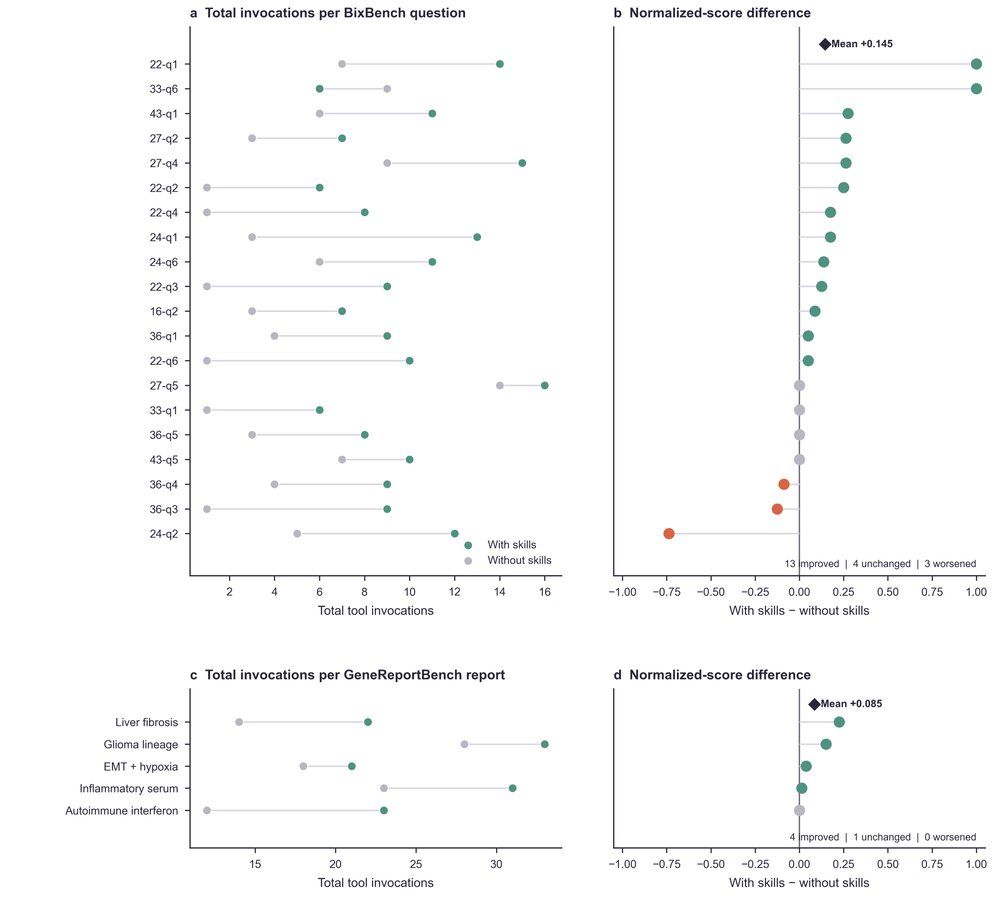

In [5]:
bix_skills_with = apply_bixbench_committee_scores(results.load_run(
    'deepseek_cli_clean_20260711',
    benchmark='bixbench',
    include_usage=False,
    include_judge_details=True,
))
bix_skills_without = apply_bixbench_committee_scores(results.load_run(
    'deepseek_cli_clean_20260713_noskills',
    benchmark='bixbench',
    include_usage=False,
    include_judge_details=True,
))
bix_skills = bix_skills_with[['item_id', 'normalized_score', 'tool_calls']].rename(columns={
    'normalized_score': 'with_score',
    'tool_calls': 'with_tool_calls',
}).merge(
    bix_skills_without[['item_id', 'normalized_score', 'tool_calls']].rename(columns={
        'normalized_score': 'without_score',
        'tool_calls': 'without_tool_calls',
    }),
    on='item_id',
    validate='one_to_one',
)
bix_skills[['with_score', 'without_score']] = bix_skills[['with_score', 'without_score']].fillna(0)
bix_skills['delta'] = bix_skills['with_score'] - bix_skills['without_score']
bix_skills = bix_skills.sort_values(['delta', 'item_id'], ascending=[False, True]).reset_index(drop=True)

grb_skills_with = results.load_run(
    'repobench_deepseek_skilled_subset5_repoids_20260727',
    benchmark='repobench',
    include_usage=False,
    include_judge_details=True,
)
grb_skills_without = results.load_run(
    'repobench_deepseek_noskills_subset5_repoids_20260728',
    benchmark='repobench',
    include_usage=False,
    include_judge_details=True,
)
grb_skills = grb_skills_with[['item_id', 'normalized_score', 'tool_call_count']].rename(columns={
    'normalized_score': 'with_score',
    'tool_call_count': 'with_tool_calls',
}).merge(
    grb_skills_without[['item_id', 'normalized_score', 'tool_call_count']].rename(columns={
        'normalized_score': 'without_score',
        'tool_call_count': 'without_tool_calls',
    }),
    on='item_id',
    validate='one_to_one',
)
grb_skills['delta'] = grb_skills['with_score'] - grb_skills['without_score']
grb_skills = grb_skills.sort_values(['delta', 'item_id'], ascending=[False, True]).reset_index(drop=True)

assert len(bix_skills) == 20 and bix_skills['item_id'].is_unique
assert np.isclose(bix_skills['with_score'].mean(), 0.49375)
assert np.isclose(bix_skills['without_score'].mean(), 0.34875)
assert ((bix_skills['delta'] > 0).sum(), (bix_skills['delta'] == 0).sum(), (bix_skills['delta'] < 0).sum()) == (13, 4, 3)
assert (int(bix_skills['with_tool_calls'].sum()), int(bix_skills['without_tool_calls'].sum())) == (196, 89)
assert len(grb_skills) == 5 and grb_skills['item_id'].is_unique
assert grb_skills[['with_score', 'without_score']].notna().all().all()
assert np.isclose(grb_skills['with_score'].mean(), 0.925)
assert np.isclose(grb_skills['without_score'].mean(), 0.840)
assert ((grb_skills['delta'] > 0).sum(), (grb_skills['delta'] == 0).sum(), (grb_skills['delta'] < 0).sum()) == (4, 1, 0)
assert (int(grb_skills['with_tool_calls'].sum()), int(grb_skills['without_tool_calls'].sum())) == (130, 95)

grb_skill_labels = {
    'biomarker-glioma_lineage_panel': 'Glioma lineage',
    'biomarker-inflammatory_serum_panel': 'Inflammatory serum',
    'disease_context-autoimmune_interferon_panel': 'Autoimmune interferon',
    'disease_context-liver_fibrosis_panel': 'Liver fibrosis',
    'mechanism-emt_hypoxia_program': 'EMT + hypoxia',
}

def plot_skills_row(
    tool_axis: plt.Axes,
    score_axis: plt.Axes,
    data: pd.DataFrame,
    labels: list[str],
    *,
    tool_letter: str,
    score_letter: str,
    unit: str,
    show_legends: bool,
) -> None:
    y = np.arange(len(data))
    draw_dumbbell(
        tool_axis,
        y,
        data['with_tool_calls'].to_numpy(),
        data['without_tool_calls'].to_numpy(),
        first_label='With skills',
        second_label='Without skills',
        first_color=PALETTE['jade'],
        second_color=PALETTE['lavender_grey'],
        size=20,
    )
    tool_axis.set_yticks(y, labels)
    tool_axis.set_ylim(len(data) + 0.7, -1.5)
    tool_axis.set_xlabel('Total tool invocations')
    set_panel_title(tool_axis, tool_letter, f'Total invocations per {unit}')

    delta = data['delta'].to_numpy()
    positive, negative, tie = delta > 0, delta < 0, delta == 0
    score_axis.axvline(0, color=PALETTE['mid_grey'], linewidth=0.75, zorder=0)
    score_axis.hlines(y, 0, delta, color=PALETTE['light_grey'], linewidth=0.8, zorder=1)
    score_axis.scatter(delta[positive], y[positive], marker='o', s=23, color=PALETTE['jade'], zorder=3, label='Improved')
    score_axis.scatter(delta[negative], y[negative], marker='o', s=23, color=PALETTE['coral'], zorder=3, label='Worsened')
    score_axis.scatter(delta[tie], y[tie], marker='o', s=23, color=PALETTE['lavender_grey'], zorder=3, label='Unchanged')
    mean_delta = float(data['delta'].mean())
    score_axis.scatter(mean_delta, -0.8, marker='D', s=27, color=PALETTE['ink'], edgecolor='white', linewidth=0.45, zorder=4)
    score_axis.text(mean_delta + 0.035, -0.8, f'Mean {mean_delta:+.3f}', va='center', fontsize=5.4, fontweight='bold')
    score_axis.set_ylim(len(data) + 0.7, -1.5)
    score_axis.set_xlim(-1.05, 1.05)
    score_axis.set_xlabel('With skills − without skills')
    score_axis.tick_params(axis='y', left=False, labelleft=False)
    set_panel_title(score_axis, score_letter, 'Normalized-score difference')
    summary = f'{positive.sum()} improved  |  {tie.sum()} unchanged  |  {negative.sum()} worsened'
    score_axis.text(1.0, len(data) + 0.25, summary, ha='right', va='center', fontsize=5.2)
    if show_legends:
        tool_axis.legend(loc='lower right')

fig = plt.figure(figsize=(PAGE_WIDTH, mm(165)))
grid = fig.add_gridspec(2, 2, height_ratios=[3.45, 1.0], hspace=0.32, wspace=0.14)
bix_tool_axis = fig.add_subplot(grid[0, 0])
bix_score_axis = fig.add_subplot(grid[0, 1])
grb_tool_axis = fig.add_subplot(grid[1, 0])
grb_score_axis = fig.add_subplot(grid[1, 1])
plot_skills_row(
    bix_tool_axis,
    bix_score_axis,
    bix_skills,
    [short_bix_label(value) for value in bix_skills['item_id']],
    tool_letter='a',
    score_letter='b',
    unit='BixBench question',
    show_legends=True,
)
plot_skills_row(
    grb_tool_axis,
    grb_score_axis,
    grb_skills,
    [grb_skill_labels[value] for value in grb_skills['item_id']],
    tool_letter='c',
    score_letter='d',
    unit='GeneReportBench report',
    show_legends=False,
)
fig.subplots_adjust(left=0.19, right=0.985, top=0.97, bottom=0.06)
save_figure(fig, 'fig5_skills_ablation')
plt.show()

### Figure 6. Performance across species-specific question sets

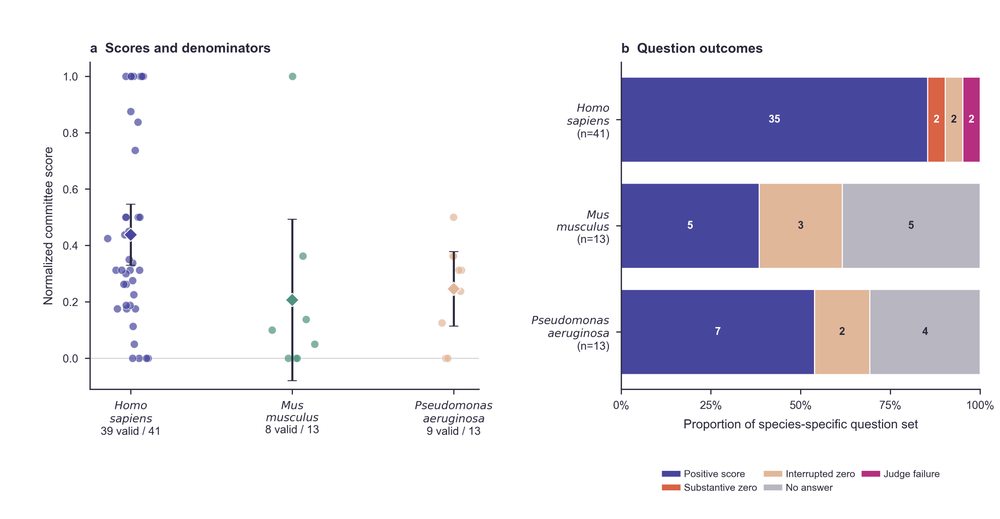

In [6]:
species_order = ['Homo sapiens', 'Mus musculus', 'Pseudomonas aeruginosa']
species_names = ['$\\mathit{Homo}$\n$\\mathit{sapiens}$', '$\\mathit{Mus}$\n$\\mathit{musculus}$', '$\\mathit{Pseudomonas}$\n$\\mathit{aeruginosa}$']
species_rows = []
for species in species_order:
    frame = study.loc[study['species'].eq(species)]
    scores = frame['normalized_score'].dropna()
    interval = score_interval(scores)
    species_rows.append({
        'species': species,
        'total': len(frame),
        'valid': len(scores),
        'zero': int(scores.eq(0).sum()),
        'missing': int(frame['normalized_score'].isna().sum()),
        'positive': int(scores.gt(0).sum()),
        'mean': scores.mean(),
        'ci_lower': interval['ci_lower'],
        'ci_upper': interval['ci_upper'],
    })
species_summary = pd.DataFrame(species_rows).set_index('species')
assert species_summary[['total', 'valid', 'zero', 'missing', 'positive']].astype(int).to_dict('index') == {
    'Homo sapiens': {'total': 41, 'valid': 39, 'zero': 4, 'missing': 2, 'positive': 35},
    'Mus musculus': {'total': 13, 'valid': 8, 'zero': 3, 'missing': 5, 'positive': 5},
    'Pseudomonas aeruginosa': {'total': 13, 'valid': 9, 'zero': 2, 'missing': 4, 'positive': 7},
}
species_labels = [
    f"{name}\n{int(species_summary.loc[species, 'valid'])} valid / {int(species_summary.loc[species, 'total'])}"
    for species, name in zip(species_order, species_names)
]

fig, axes = plt.subplots(1, 2, figsize=(PAGE_WIDTH, mm(95)), gridspec_kw={'width_ratios': [1.04, 0.96], 'wspace': 0.38})
rng = np.random.default_rng(20260718)
ci_lowers = []
for index, species in enumerate(species_order):
    values = study.loc[study['species'].eq(species), 'normalized_score'].dropna().to_numpy()
    x_values = rng.normal(index, 0.045, len(values))
    color = SPECIES_COLORS[species]
    axes[0].scatter(x_values, values, s=17, marker='o', color=color, alpha=0.70, edgecolor='white', linewidth=0.3)
    record = species_summary.loc[species]
    ci_lowers.append(record['ci_lower'])
    axes[0].errorbar(
        index, record['mean'],
        yerr=np.array([[record['mean'] - record['ci_lower']], [record['ci_upper'] - record['mean']]]),
        fmt='D', color=PALETTE['ink'], markerfacecolor=color, markeredgecolor='white', markeredgewidth=0.45,
        markersize=5.0, capsize=2.4, linewidth=1.05, zorder=4,
    )
axes[0].axhline(0, color=PALETTE['light_grey'], linewidth=0.6, zorder=0)
axes[0].set_xticks(range(3), species_labels)
axes[0].set_ylabel('Normalized committee score')
axes[0].set_ylim(min(-0.08, np.nanmin(ci_lowers) - 0.03), 1.05)
set_panel_title(axes[0], 'a', 'Scores and denominators')

composition = pd.crosstab(study['species'], study['outcome_class']).reindex(index=species_order, columns=OUTCOME_ORDER, fill_value=0)
assert composition.astype(int).to_dict('index') == {
    'Homo sapiens': {'positive_score': 35, 'substantive_zero': 2, 'interrupted_zero': 2, 'no_answer': 0, 'judge_failure': 2},
    'Mus musculus': {'positive_score': 5, 'substantive_zero': 0, 'interrupted_zero': 3, 'no_answer': 5, 'judge_failure': 0},
    'Pseudomonas aeruginosa': {'positive_score': 7, 'substantive_zero': 0, 'interrupted_zero': 2, 'no_answer': 4, 'judge_failure': 0},
}
proportions = composition.div(composition.sum(axis=1), axis=0)
left = np.zeros(len(species_order))
for outcome in OUTCOME_ORDER:
    values = proportions[outcome].to_numpy()
    counts = composition[outcome].to_numpy()
    axes[1].barh(range(3), values, left=left, color=OUTCOME_COLORS[outcome], edgecolor='white', linewidth=0.55, label=OUTCOME_LABELS[outcome])
    for index, (value, count) in enumerate(zip(values, counts)):
        if count:
            text_color = 'white' if outcome in {'positive_score', 'substantive_zero', 'judge_failure'} else PALETTE['ink']
            axes[1].text(left[index] + value / 2, index, str(int(count)), ha='center', va='center', fontsize=5.5, color=text_color, fontweight='bold')
    left += values
axes[1].set_yticks(range(3), [f'{name}\n(n={int(species_summary.loc[species, "total"])})' for species, name in zip(species_order, species_names)])
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xticks([0, 0.25, 0.50, 0.75, 1.00])
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].set_xlabel('Proportion of species-specific question set')
set_panel_title(axes[1], 'b', 'Question outcomes')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=5.1, columnspacing=0.6, handletextpad=0.3)
fig.subplots_adjust(left=0.09, right=0.98, top=0.88, bottom=0.25)
save_figure(fig, 'fig6_species_cohorts')
plt.show()


## Extended Data figures

### Extended Data Figure 2. Paired BixBench model selection

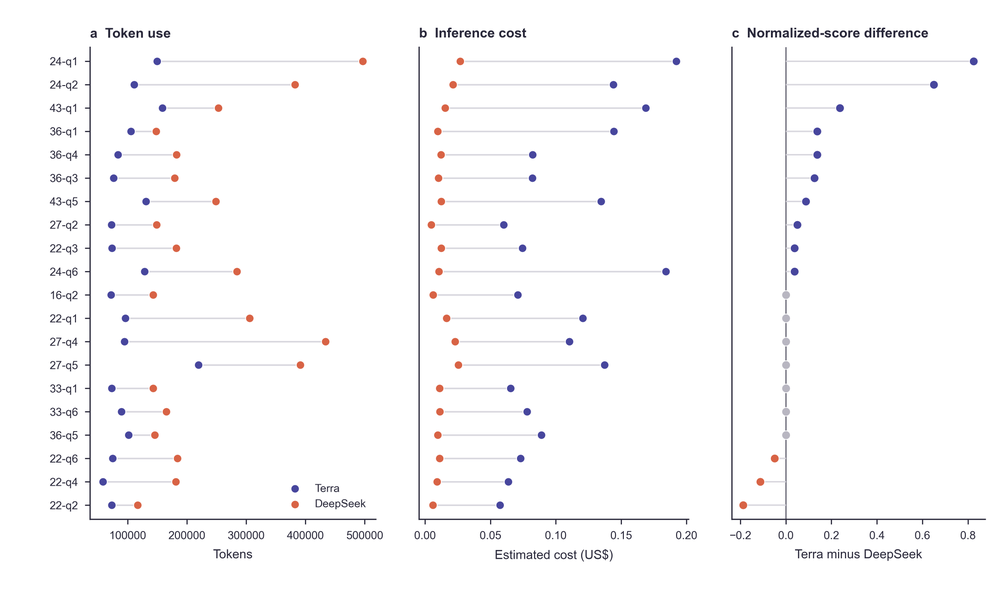

In [7]:
PRICING = {
    'Terra': {'input_per_mtok': 2.50, 'output_per_mtok': 15.00, 'cache_read_per_mtok': 0.25},
    'DeepSeek': {'input_per_mtok': 0.077, 'output_per_mtok': 0.154, 'cache_read_per_mtok': 0.0154},
}
bix_comparison = results.compare_runs(
    'terra_cli_clean_20260710',
    'deepseek_cli_clean_20260711',
    benchmark='bixbench',
    include_usage=True,
    include_bixbench_metadata=True,
    include_judge_details=True,
)
bix_paired = bix_comparison.paired.copy()
assert len(bix_paired) == 20
left_committee = apply_bixbench_committee_scores(bix_comparison.left_data).set_index('item_id')['normalized_score']
right_committee = apply_bixbench_committee_scores(bix_comparison.right_data).set_index('item_id')['normalized_score']
bix_paired['left_normalized_score'] = bix_paired['item_id'].map(left_committee)
bix_paired['right_normalized_score'] = bix_paired['item_id'].map(right_committee)
for side, model in [('left', 'Terra'), ('right', 'DeepSeek')]:
    bix_paired[f'{side}_total_tokens'] = bix_paired[[f'{side}_tokens_input', f'{side}_tokens_output', f'{side}_tokens_reasoning', f'{side}_tokens_cache_read']].sum(axis=1)
    bix_paired[f'{side}_cost'] = (
        bix_paired[f'{side}_tokens_input'] * PRICING[model]['input_per_mtok']
        + (bix_paired[f'{side}_tokens_output'] + bix_paired[f'{side}_tokens_reasoning']) * PRICING[model]['output_per_mtok']
        + bix_paired[f'{side}_tokens_cache_read'] * PRICING[model]['cache_read_per_mtok']
    ) / 1_000_000
bix_paired['delta'] = bix_paired['left_normalized_score'] - bix_paired['right_normalized_score']
bix_paired = bix_paired.sort_values(['delta', 'item_id'], ascending=[False, True]).reset_index(drop=True)
y = np.arange(len(bix_paired))

fig, axes = plt.subplots(1, 3, figsize=(PAGE_WIDTH, mm(108)), sharey=True, gridspec_kw={'width_ratios': [1.06, 1.0, 0.94], 'wspace': 0.16})
draw_dumbbell(
    axes[0], y,
    bix_paired['left_total_tokens'].to_numpy(), bix_paired['right_total_tokens'].to_numpy(),
    first_label='Terra', second_label='DeepSeek',
    first_color=MODEL_COLORS['Terra'], second_color=MODEL_COLORS['DeepSeek'],
    size=19,
)
axes[0].set_yticks(y, [short_bix_label(value) for value in bix_paired['item_id']])
axes[0].set_ylim(len(bix_paired) - 0.4, -0.6)
axes[0].set_xlabel('Tokens')
set_panel_title(axes[0], 'a', 'Token use')
axes[0].legend(loc='lower right')

draw_dumbbell(
    axes[1], y,
    bix_paired['left_cost'].to_numpy(), bix_paired['right_cost'].to_numpy(),
    first_label='Terra', second_label='DeepSeek',
    first_color=MODEL_COLORS['Terra'], second_color=MODEL_COLORS['DeepSeek'],
    size=19,
)
axes[1].set_xlabel('Estimated cost (US$)')
axes[1].tick_params(axis='y', left=False, labelleft=False)
set_panel_title(axes[1], 'b', 'Inference cost')

axes[2].axvline(0, color=PALETTE['mid_grey'], linewidth=0.7)
axes[2].hlines(y, 0, bix_paired['delta'], color=PALETTE['light_grey'], linewidth=0.75)
for index, row in bix_paired.iterrows():
    if row['delta'] > 0:
        color = MODEL_COLORS['Terra']
    elif row['delta'] < 0:
        color = MODEL_COLORS['DeepSeek']
    else:
        color = PALETTE['lavender_grey']
    axes[2].scatter(row['delta'], index, s=20, marker='o', color=color, edgecolor='white', linewidth=0.4, zorder=3)
axes[2].set_xlabel('Terra minus DeepSeek')
axes[2].tick_params(axis='y', left=False, labelleft=False)
set_panel_title(axes[2], 'c', 'Normalized-score difference')
fig.subplots_adjust(left=0.09, right=0.985, top=0.92, bottom=0.12)
save_figure(fig, 'ed_fig2_bixbench_model_selection')
plt.show()


### Extended Data Figure 3. Metadata-driven BixBench categories

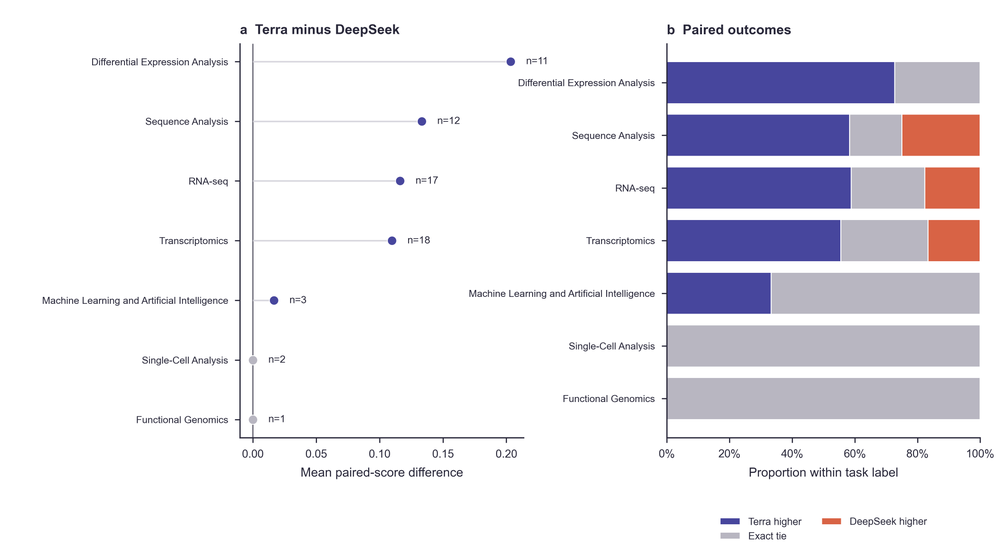

In [8]:
metadata_pairs = bix_paired[['item_id', 'delta', 'left_species', 'left_task_categories']].rename(columns={'left_species': 'species', 'left_task_categories': 'task_categories'})
assert metadata_pairs['species'].eq('Homo sapiens').all()
metadata_tasks = EvaluationResults.explode_bixbench_categories(metadata_pairs)
task_summary = metadata_tasks.groupby('task_category', sort=False).agg(
    questions=('item_id', 'nunique'),
    terra_wins=('delta', lambda values: values.gt(0).sum()),
    exact_ties=('delta', lambda values: values.eq(0).sum()),
    deepseek_wins=('delta', lambda values: values.lt(0).sum()),
    mean_delta=('delta', 'mean'),
).sort_values(['questions', 'task_category'], ascending=[True, True])
plot_data = task_summary.sort_values('mean_delta')
y = np.arange(len(plot_data))

fig, axes = plt.subplots(1, 2, figsize=(PAGE_WIDTH, mm(100)), gridspec_kw={'width_ratios': [0.95, 1.05], 'wspace': 0.48})
axes[0].axvline(0, color=PALETTE['mid_grey'], linewidth=0.7)
axes[0].hlines(y, 0, plot_data['mean_delta'], color=PALETTE['light_grey'], linewidth=0.8)
for index, row in enumerate(plot_data.itertuples()):
    nonnegative = row.mean_delta >= 0
    if row.mean_delta > 0:
        color = MODEL_COLORS['Terra']
    elif row.mean_delta < 0:
        color = MODEL_COLORS['DeepSeek']
    else:
        color = PALETTE['lavender_grey']
    axes[0].scatter(row.mean_delta, index, marker='o', s=23, color=color, edgecolor='white', linewidth=0.4, zorder=3)
    offset = 0.012 if nonnegative else -0.012
    axes[0].text(row.mean_delta + offset, index, f'n={row.questions}', va='center', ha='left' if nonnegative else 'right', fontsize=5.3)
axes[0].set_yticks(y, plot_data.index)
axes[0].set_xlabel('Mean paired-score difference')
set_panel_title(axes[0], 'a', 'Terra minus DeepSeek')

proportions = plot_data[['terra_wins', 'exact_ties', 'deepseek_wins']].div(plot_data['questions'], axis=0)
left = np.zeros(len(plot_data))
for column, label, color in [
    ('terra_wins', 'Terra higher', MODEL_COLORS['Terra']),
    ('exact_ties', 'Exact tie', PALETTE['lavender_grey']),
    ('deepseek_wins', 'DeepSeek higher', MODEL_COLORS['DeepSeek']),
]:
    values = proportions[column].to_numpy()
    axes[1].barh(y, values, left=left, color=color, label=label, edgecolor='white', linewidth=0.5)
    left += values
axes[1].set_yticks(y, plot_data.index)
axes[1].set_xlim(0, 1)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[1].set_xlabel('Proportion within task label')
set_panel_title(axes[1], 'b', 'Paired outcomes')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=5.2)
for axis in axes:
    axis.tick_params(axis='y', labelsize=5.1)
fig.subplots_adjust(left=0.24, right=0.98, top=0.92, bottom=0.20)
save_figure(fig, 'ed_fig3_bixbench_metadata_categories')
plt.show()


### Extended Data Figure 4. Paired GeneReportBench model selection

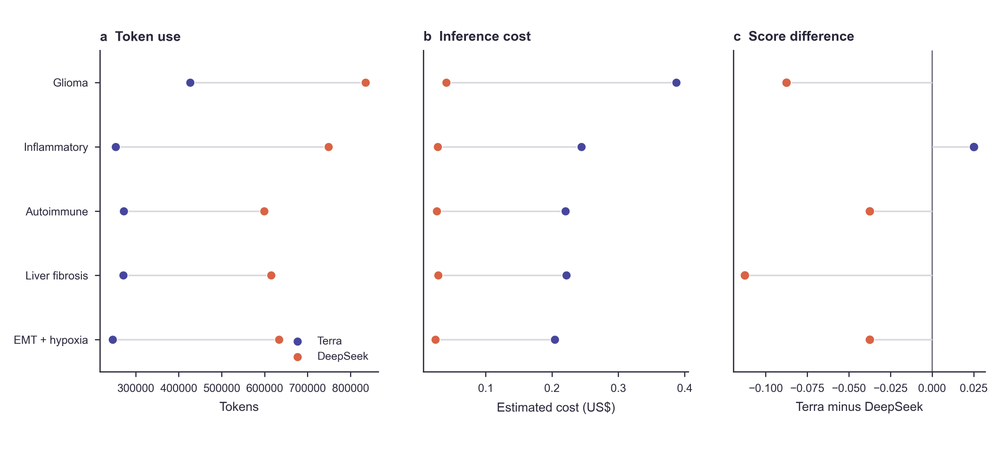

In [9]:
REPO_TASK_ORDER = [
    'biomarker-glioma_lineage_panel',
    'biomarker-inflammatory_serum_panel',
    'disease_context-autoimmune_interferon_panel',
    'disease_context-liver_fibrosis_panel',
    'mechanism-emt_hypoxia_program',
]
repo_deepseek = results.load_run('repobench_deepseek_skilled_subset5_repoids_20260727', benchmark='repobench', include_usage=False)
repo_terra = results.load_run('repobench_terra_skilled_subset5_repoids_20260728', benchmark='repobench', include_usage=False)
repo_deepseek = repo_deepseek.merge(extract_repobench_usage(ROOT / 'var' / 'repobench' / 'runs' / 'repobench_deepseek_skilled_subset5_repoids_20260727'), on='item_id', validate='one_to_one')
repo_terra = repo_terra.merge(extract_repobench_usage(ROOT / 'var' / 'repobench' / 'runs' / 'repobench_terra_skilled_subset5_repoids_20260728'), on='item_id', validate='one_to_one')
repo_deepseek = add_costs(repo_deepseek, PRICING['DeepSeek'])
repo_terra = add_costs(repo_terra, PRICING['Terra'])
repo_paired = repo_terra.set_index('item_id').add_prefix('terra_').join(repo_deepseek.set_index('item_id').add_prefix('deepseek_'), how='inner').reindex(REPO_TASK_ORDER).reset_index()
assert len(repo_paired) == 5 and repo_paired['item_id'].notna().all()
repo_paired['delta'] = repo_paired['terra_normalized_score'] - repo_paired['deepseek_normalized_score']
labels = ['Glioma', 'Inflammatory', 'Autoimmune', 'Liver fibrosis', 'EMT + hypoxia']
y = np.arange(len(repo_paired))

fig, axes = plt.subplots(1, 3, figsize=(PAGE_WIDTH, mm(84)), sharey=True, gridspec_kw={'width_ratios': [1.05, 1.0, 0.95], 'wspace': 0.17})
draw_dumbbell(
    axes[0], y,
    repo_paired['terra_total_tokens'].to_numpy(), repo_paired['deepseek_total_tokens'].to_numpy(),
    first_label='Terra', second_label='DeepSeek', first_color=MODEL_COLORS['Terra'], second_color=MODEL_COLORS['DeepSeek'],
    size=22,
)
axes[0].set_yticks(y, labels)
axes[0].set_ylim(len(repo_paired) - 0.5, -0.5)
axes[0].set_xlabel('Tokens')
set_panel_title(axes[0], 'a', 'Token use')
axes[0].legend(loc='lower right')

draw_dumbbell(
    axes[1], y,
    repo_paired['terra_estimated_cost_usd'].to_numpy(), repo_paired['deepseek_estimated_cost_usd'].to_numpy(),
    first_label='Terra', second_label='DeepSeek', first_color=MODEL_COLORS['Terra'], second_color=MODEL_COLORS['DeepSeek'],
    size=22,
)
axes[1].set_xlabel('Estimated cost (US$)')
axes[1].tick_params(axis='y', left=False, labelleft=False)
set_panel_title(axes[1], 'b', 'Inference cost')

axes[2].axvline(0, color=PALETTE['mid_grey'], linewidth=0.7)
axes[2].hlines(y, 0, repo_paired['delta'], color=PALETTE['light_grey'], linewidth=0.8)
for index, row in repo_paired.iterrows():
    if row['delta'] > 0:
        color = MODEL_COLORS['Terra']
    elif row['delta'] < 0:
        color = MODEL_COLORS['DeepSeek']
    else:
        color = PALETTE['lavender_grey']
    axes[2].scatter(row['delta'], index, marker='o', s=23, color=color, edgecolor='white', linewidth=0.4, zorder=3)
axes[2].set_xlabel('Terra minus DeepSeek')
axes[2].tick_params(axis='y', left=False, labelleft=False)
set_panel_title(axes[2], 'c', 'Score difference')
fig.subplots_adjust(left=0.10, right=0.985, top=0.89, bottom=0.19)
save_figure(fig, 'ed_fig4_genereportbench_model_selection')
plt.show()


### Extended Data Figure 5. Findings associated with zero-score outcomes

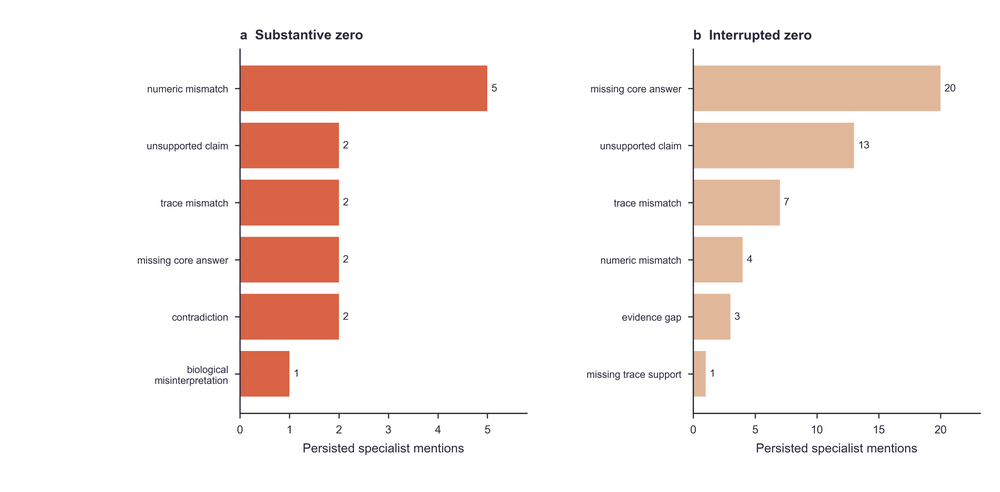

In [10]:
failure_rows = []
for outcome, label in [('substantive_zero', 'Substantive zero'), ('interrupted_zero', 'Interrupted zero')]:
    cohort = study.loc[study['outcome_class'].eq(outcome)]
    for role, column in {
        'Statistics': 'judge_stats_failure_codes',
        'Biology': 'judge_biology_failure_codes',
        'Evidence': 'judge_evidence_failure_codes',
    }.items():
        counts = Counter(item for value in cohort[column].dropna() for item in split_values(value))
        failure_rows.extend({'outcome': label, 'role': role, 'finding': finding, 'count': count} for finding, count in counts.items())
failure_codes = pd.DataFrame(failure_rows)

fig, axes = plt.subplots(1, 2, figsize=(PAGE_WIDTH, mm(90)), gridspec_kw={'wspace': 0.58})
for axis, label, color in [
    (axes[0], 'Substantive zero', OUTCOME_COLORS['substantive_zero']),
    (axes[1], 'Interrupted zero', OUTCOME_COLORS['interrupted_zero']),
]:
    table = failure_codes.loc[failure_codes['outcome'].eq(label)].groupby('finding', as_index=False)['count'].sum().sort_values(['count', 'finding']).tail(10)
    bars = axis.barh(table['finding'].str.replace('_', ' ').map(lambda value: fill(value, 24)), table['count'], color=color)
    axis.bar_label(bars, labels=[str(int(value)) for value in table['count']], padding=2, fontsize=5.4, color=PALETTE['ink'])
    axis.set_xlim(0, table['count'].max() * 1.16)
    axis.set_xlabel('Persisted specialist mentions')
    set_panel_title(axis, 'a' if axis is axes[0] else 'b', label)
    axis.tick_params(axis='y', labelsize=5.2)
fig.subplots_adjust(left=0.24, right=0.98, top=0.90, bottom=0.16)
save_figure(fig, 'ed_fig5_bixbench_failure_findings')
plt.show()


## Extended Data tables

### Extended Data Table 1. GeneReportBench task-level quality outcomes

In [11]:
grb_quality = pd.DataFrame({
    'Task': grb['question_id'],
    'Report type': grb['report_type'].map(FAMILY_LABELS),
    'Final': grb['normalized_score'],
    'B': grb['Biomedical content'].astype(int),
    'E': grb['Evidence support'].astype(int),
    'P': grb['Provenance quality'].astype(int),
    'T': grb['Template compliance'].astype(int),
})
display(grb_quality.style.format({'Final': SCORE_FORMAT}))
save_table(grb_quality, 'ed_table1_grb_quality', column_format='p{2.2cm}p{2.7cm}rrrrr', formatters={'Final': lambda value: SCORE_FORMAT.format(value)})

,Task,Report type,Final,B,E,P,T
0,repo-1-q1,Biomarker,0.925,4,3,4,4
1,repo-2-q1,Biomarker,0.850,4,3,2,4
2,repo-3-q1,Biomarker,0.925,4,3,4,4
3,repo-4-q1,Biomarker,0.688,3,2,2,4
4,repo-5-q1,Biomarker,0.700,4,1,2,4
5,repo-6-q1,Disease context,1.000,4,4,4,4
6,repo-7-q1,Disease context,0.963,4,4,3,4
7,repo-8-q1,Disease context,0.925,4,3,4,4
8,repo-9-q1,Disease context,0.925,4,3,4,4
9,repo-10-q1,Disease context,1.000,4,4,4,4


### Extended Data Table 2. GeneReportBench retained workflow materials

In [12]:
grb_workflow = pd.DataFrame({
    'Task': grb['question_id'],
    'Short title': grb['title'],
    'Artifacts': grb['linked_artifact_count'].astype(int),
    'Words': grb['final_report_word_count'].astype(int),
    'Total tool calls': grb['tool_call_count'].astype(int),
})
display(grb_workflow)
save_table(grb_workflow, 'ed_table2_grb_workflow', column_format='p{2.2cm}p{5.0cm}rrr')

,Task,Short title,Artifacts,Words,Total tool calls
0,repo-1-q1,Epithelial tumor biomarker panel,11,3738,31
1,repo-2-q1,Inflammatory serum marker shortlist,16,2761,31
2,repo-3-q1,Glioma lineage and invasion panel,18,3686,33
3,repo-4-q1,Fibrosis extracellular matrix panel,11,2680,28
4,repo-5-q1,Cardio-inflammatory biomarker shortlist,13,3151,26
5,repo-6-q1,Inflammatory bowel disease panel,12,2623,22
6,repo-7-q1,Microglial neurodegeneration panel,7,2306,21
7,repo-8-q1,Pulmonary fibrosis panel,11,2538,25
8,repo-9-q1,Autoimmune interferon panel,13,2270,23
9,repo-10-q1,Liver fibrosis and susceptibility panel,9,1934,22


### Extended Data Table 3. Scope-aware BixBench outcome accounting

In [13]:
scope_frames = [('All in-scope', study)] + [(species, study.loc[study['species'].eq(species)]) for species in species_order]
scope_rows = []
summary_rows = []
for label, frame in scope_frames:
    scores = frame['normalized_score'].dropna()
    positives = scores.loc[scores.gt(0)]
    judge_failures = int(frame['outcome_class'].eq('judge_failure').sum())
    no_answer_zero_denominator = len(frame) - judge_failures
    mean_no_answer_zero = scores.sum() / no_answer_zero_denominator
    all_interval = score_interval(scores)
    positive_interval = score_interval(positives)
    scope_rows.append({
        'Cohort': label,
        'Total': len(frame),
        'Valid': len(scores),
        'Positive': int(scores.gt(0).sum()),
        'Zero': int(scores.eq(0).sum()),
        'No answer': int(frame['outcome_class'].eq('no_answer').sum()),
        'Judge failure': judge_failures,
        'Mean valid': scores.mean(),
        'Mean no-answer=0': mean_no_answer_zero,
    })
    summary_rows.append({
        'cohort': 'All in-scope questions' if label == 'All in-scope' else 'Species',
        'scope': 'All species combined' if label == 'All in-scope' else label,
        'total_questions': len(frame),
        'valid_committee_scores': len(scores),
        'positive_scores': int(scores.gt(0).sum()),
        'substantive_zeroes': int(frame['outcome_class'].eq('substantive_zero').sum()),
        'interrupted_zeroes': int(frame['outcome_class'].eq('interrupted_zero').sum()),
        'no_answers': int(frame['outcome_class'].eq('no_answer').sum()),
        'judge_failures': judge_failures,
        'no_answer_zero_denominator': no_answer_zero_denominator,
        'mean_valid_scores': all_interval['mean'],
        'se_valid_scores': all_interval['se'],
        'ci95_lower_valid_scores': all_interval['ci_lower'],
        'ci95_upper_valid_scores': all_interval['ci_upper'],
        'mean_no_answer_zero': mean_no_answer_zero,
        'mean_positive_scores_only': positive_interval['mean'],
        'se_positive_scores_only': positive_interval['se'],
        'ci95_lower_positive_only': positive_interval['ci_lower'],
        'ci95_upper_positive_only': positive_interval['ci_upper'],
    })
bix_accounting = pd.DataFrame(scope_rows)
assert bix_accounting[['Total', 'Valid', 'Positive', 'Zero', 'No answer', 'Judge failure']].astype(int).to_dict('records') == [
    {'Total': 67, 'Valid': 56, 'Positive': 47, 'Zero': 9, 'No answer': 9, 'Judge failure': 2},
    {'Total': 41, 'Valid': 39, 'Positive': 35, 'Zero': 4, 'No answer': 0, 'Judge failure': 2},
    {'Total': 13, 'Valid': 8, 'Positive': 5, 'Zero': 3, 'No answer': 5, 'Judge failure': 0},
    {'Total': 13, 'Valid': 9, 'Positive': 7, 'Zero': 2, 'No answer': 4, 'Judge failure': 0},
]
assert np.allclose(bix_accounting['Mean valid'], [0.374, 0.438, 0.206, 0.246], atol=0.0005)
assert np.allclose(bix_accounting['Mean no-answer=0'], [0.322, 0.438, 0.127, 0.170], atol=0.0005)
display(bix_accounting.style.format({'Mean valid': SCORE_FORMAT, 'Mean no-answer=0': SCORE_FORMAT}))
species_latex = {species: rf'\emph{{{species}}}' for species in species_order}
save_table(bix_accounting, 'ed_table3_bix_accounting', column_format='lrrrrrrrr', formatters={'Cohort': lambda value: species_latex.get(value, value), 'Mean valid': lambda value: SCORE_FORMAT.format(value), 'Mean no-answer=0': lambda value: SCORE_FORMAT.format(value)})

grb_supplement = pd.DataFrame({
    'task_id': grb['item_id'],
    'question_id': grb['question_id'],
    'title': grb['title'],
    'report_type': grb['report_type'],
    'domain': grb['domain'],
    'final_normalized_committee_score': grb['normalized_score'],
    'committee_level_0_to_4': grb['score_0_4'],
    'committee_category': grb['committee_category_label'],
    'biomedical_content_level': grb['Biomedical content'],
    'evidence_support_level': grb['Evidence support'],
    'provenance_quality_level': grb['Provenance quality'],
    'template_compliance_level': grb['Template compliance'],
    'linked_artifact_count': grb['linked_artifact_count'],
    'final_report_word_count': grb['final_report_word_count'],
    'tool_call_count': grb['tool_call_count'],
})
grb_supplement.to_csv(TABLE_DIR / 'genereportbench_task_level_results.csv', index=False)
pd.DataFrame(summary_rows).to_csv(TABLE_DIR / 'bixbench_scope_aware_summary.csv', index=False)

,Cohort,Total,Valid,Positive,Zero,No answer,Judge failure,Mean valid,Mean no-answer=0
0,All in-scope,67,56,47,9,9,2,0.374,0.322
1,Homo sapiens,41,39,35,4,0,2,0.438,0.438
2,Mus musculus,13,8,5,3,5,0,0.206,0.127
3,Pseudomonas aeruginosa,13,9,7,2,4,0,0.246,0.170


## Interpretation boundaries

GeneReportBench describes 15 curated report-generation tasks and is not a population estimate. BixBench committee scores are direct weighted means of the three saved specialist verdicts. Valid-score means exclude no answers and judge failures. Conservative question-level means assign zero to no answers while excluding judge failures. Species-specific sets contain different cases, so their differences do not estimate an isolated species effect. Outcome classes are mutually exclusive, positive-only summaries are conditional, and task categories overlap. None of these figures isolates the causal effect of MCP.

## Output validation


In [14]:
EXPECTED_PNG = [
    'fig3_genereportbench_results.png',
    'fig4_bixbench_results.png',
    'fig5_skills_ablation.png',
    'fig6_species_cohorts.png',
    'ed_fig2_bixbench_model_selection.png',
    'ed_fig3_bixbench_metadata_categories.png',
    'ed_fig4_genereportbench_model_selection.png',
    'ed_fig5_bixbench_failure_findings.png',
]
EXPECTED_PDF = [Path(name).with_suffix('.pdf').name for name in EXPECTED_PNG]
EXPECTED_TABLES = ['ed_table1_grb_quality.tex', 'ed_table2_grb_workflow.tex', 'ed_table3_bix_accounting.tex']
assert sorted(path.name for path in FIGURE_DIR.glob('*.png')) == sorted(EXPECTED_PNG)
assert sorted(path.name for path in FIGURE_DIR.glob('*.pdf')) == sorted(EXPECTED_PDF)
assert sorted(path.name for path in TABLE_DIR.glob('*.tex')) == sorted(EXPECTED_TABLES)
assert len(EXPECTED_PNG) == 8 and len(EXPECTED_PDF) == 8 and len(EXPECTED_TABLES) == 3
assert len(FIGURE_AUDIT) == 8
assert all(np.isclose(row['width_mm'], 183.0, atol=1e-6) for row in FIGURE_AUDIT)
assert all(row['height_mm'] <= 170.0 and row['gridlines'] == 0 for row in FIGURE_AUDIT)

display(pd.DataFrame(FIGURE_AUDIT))
display(pd.DataFrame({
    'logical outputs': ['PNG figures', 'Vector PDFs', 'Tables'],
    'count': [len(EXPECTED_PNG), len(EXPECTED_PDF), len(EXPECTED_TABLES)],
    'location': [str(FIGURE_DIR.relative_to(ROOT)), str(FIGURE_DIR.relative_to(ROOT)), str(TABLE_DIR.relative_to(ROOT))],
}))


,stem,width_mm,height_mm,gridlines
0,fig3_genereportbench_results,183.0,155.0,0
1,fig4_bixbench_results,183.0,135.0,0
2,fig5_skills_ablation,183.0,165.0,0
3,fig6_species_cohorts,183.0,95.0,0
4,ed_fig2_bixbench_model_selection,183.0,108.0,0
5,ed_fig3_bixbench_metadata_categories,183.0,100.0,0
6,ed_fig4_genereportbench_model_selection,183.0,84.0,0
7,ed_fig5_bixbench_failure_findings,183.0,90.0,0


,logical outputs,count,location
0,PNG figures,8,notebooks/eval/paper_outputs/figures
1,Vector PDFs,8,notebooks/eval/paper_outputs/figures
2,Tables,3,notebooks/eval/paper_outputs/tables
